<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [National Hockey League Data](https://github.com/Query-farm/vgi-nhl)

NHL standings, scores, play-by-play, and player statistics as SQL tables.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nhl/blob/main/notebooks/02_reconcile_the_opener.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nhl/blob/main/notebooks/README.md)


## One final score, several reporting grains

**Do the day scoreboard, weekly schedule, club schedule and player box scores describe the same game—and which goalies have a meaningful save rate?** Reconcile Chicago at Florida, game 2025020001 on 2025-10-07. Keep unused goalies in the result without interpreting zero shots as a zero save percentage.

**Real public NHL responses, recorded independently on 2026-11-15 UTC.**
The default replays unchanged response bodies through the real released worker.
These are historical observations, not a synthetic scenario or an atomic live
snapshot. The [provenance manifest](recordings/provenance.json) records exact URLs,
request parameters, acquisition times and hashes. All joins and choices remain visible SQL.

### Choose one local rule

`MIN_SHOTS` is an integer 1–100. It controls eligibility for the goalie-rate comparison, not which goalies are retrieved. Change 20→1 to include every goalie who faced a shot.

In [1]:
DATA_MODE = "replay"
MIN_SHOTS = 20

In [2]:
import importlib.metadata

try:
    _shared_version = importlib.metadata.version("vgi-example-notebooks")
except importlib.metadata.PackageNotFoundError:
    _shared_version = None
if _shared_version != "0.3.49":
    %pip -q install "vgi-example-notebooks @ git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.49"
from vgi_notebooks import check_runtime
from vgi_notebooks.bootstrap import prepare

check_runtime()
_companion_directory = prepare("nhl")

In [3]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from nhl_examples import NHLExample

if type(MIN_SHOTS) is not int or not 1 <= MIN_SHOTS <= 100:
    raise ValueError("MIN_SHOTS must be an integer from 1 through 100")
source = NHLExample(DATA_MODE, "games")
theme()
session = connect(globals())
SOURCE = (
    "Recorded public NHL responses · captured 2026-11-15 UTC"
    if DATA_MODE == "replay"
    else "Live public NHL responses · independent endpoint reads"
) + " · worker v0.2.0"

### Attach the released worker

The public tag owns dependencies in an isolated Python 3.13 worker environment.
Shared base tooling leaves the kernel intact and starts UTC with an empty temporary
SQL-secret store and persistence disabled. The replay helper redirects all NHL roots
to loopback, verifies response hashes and rejects requests outside this scenario.
Live mode clears inherited URL overrides and never falls back to replay.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nhl' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-nhl@v0.2.0 vgi-nhl');

,Success


### Establish the game key before comparing quantities

The day `scores` result covers three games; `schedule` covers a week and
`team_schedule` includes Florida's preseason and regular season. Keep their complete
responses, then select the same game ID. Scores and schedule rows have different
optional fields: scoreboard shots are not missing shots in the schedule, and a
schedule's winning-goalie ID is not a scoreboard requirement.

In [5]:
%%sql
CREATE TABLE day_scores AS SELECT * FROM nhl.main.scores(date:=DATE '2025-10-07');
CREATE TABLE week_schedule AS SELECT * FROM nhl.main.schedule(date:=DATE '2025-10-07');
CREATE TABLE club_schedule AS SELECT * FROM nhl.main.team_schedule('FLA',season:=20252026);
CREATE TABLE game_versions AS
 SELECT 'Day scores' AS source,* FROM day_scores WHERE game_id=2025020001
 UNION ALL SELECT 'Week schedule',* FROM week_schedule WHERE game_id=2025020001
 UNION ALL SELECT 'Club schedule',* FROM club_schedule WHERE game_id=2025020001;

,Count


In [6]:
%%sql scopes <<
SELECT source,count(*) AS rows,count(DISTINCT game_id) AS game_keys,
 min(game_date) AS first_date,max(game_date) AS last_date,
 count(*) FILTER(WHERE game_type=2) AS regular_season_games FROM (
 SELECT 'Day scores' source,* FROM day_scores UNION ALL
 SELECT 'Week schedule',* FROM week_schedule UNION ALL SELECT 'Club schedule',* FROM club_schedule
) GROUP BY source ORDER BY source;

In [7]:
display(scopes)
prose(
    "These are three differently scoped listings, not three independent games. "
    f"The club response includes **{int(scopes.loc[scopes.source == 'Club schedule', 'rows'].iloc[0])}** rows "
    "before game-type selection; the following comparison uses the shared game ID."
)

,source,rows,game_keys,first_date,last_date,regular_season_games
0,Club schedule,89,89,2025-09-21,2026-04-15,82
1,Day scores,3,3,2025-10-07,2025-10-07,3
2,Week schedule,48,48,2025-10-07,2025-10-13,48


These are three differently scoped listings, not three independent games. The club response includes **89** rows before game-type selection; the following comparison uses the shared game ID.

In [8]:
%%sql versions <<
SELECT source,game_id,season,game_type,game_date,start_time_utc,away_team_abbrev,away_score,
 home_team_abbrev,home_score,away_shots_on_goal,home_shots_on_goal,winning_goalie_id
FROM game_versions ORDER BY source;

In [9]:
display(versions)

,source,game_id,season,game_type,game_date,start_time_utc,away_team_abbrev,away_score,home_team_abbrev,home_score,away_shots_on_goal,home_shots_on_goal,winning_goalie_id
0,Club schedule,2025020001,20252026,2,2025-10-07,2025-10-07 21:00:00+00:00,CHI,2,FLA,3,<NA>,<NA>,8475683
1,Day scores,2025020001,20252026,2,2025-10-07,2025-10-07 21:00:00+00:00,CHI,2,FLA,3,19,37,<NA>
2,Week schedule,2025020001,20252026,2,2025-10-07,2025-10-07 21:00:00+00:00,CHI,2,FLA,3,<NA>,<NA>,8475683


### Aggregate players before joining the game row

`box_score` is one skater per game. `box_score_goalies` is a separate goalie grain
and includes unused backups. Aggregate skater goals by team first; compare them
with the final score and with the opposing goalies' goals against. This particular
regulation game reconciles without an unexplained residual. That observation is
not an identity for all hockey games: empty-net and shootout handling need their
own analysis when present.

In [10]:
%%sql
CREATE TABLE skaters AS SELECT * FROM nhl.main.box_score(2025020001);
CREATE TABLE goalies AS SELECT * FROM nhl.main.box_score_goalies(2025020001);
CREATE TABLE team_audit AS
WITH s AS (SELECT team_side,team_abbrev,sum(goals) skater_goals,sum(shots_on_goal) skater_shots FROM skaters GROUP BY ALL),
 g AS (SELECT team_side,sum(goals_against) allowed,sum(shots_against) faced FROM goalies GROUP BY ALL),
 scores AS (SELECT 'away' side,away_score goals,away_shots_on_goal shots FROM day_scores WHERE game_id=2025020001
 UNION ALL SELECT 'home',home_score,home_shots_on_goal FROM day_scores WHERE game_id=2025020001)
SELECT s.*,scores.goals scoreboard_goals,scores.shots scoreboard_shots,
 g.allowed opposing_goalie_goals,g.faced opposing_goalie_shots
FROM s JOIN scores ON s.team_side=scores.side JOIN g ON s.team_side<>g.team_side;

,Count


In [11]:
%%sql audit <<
SELECT * FROM team_audit ORDER BY team_abbrev;

,team_side,team_abbrev,skater_goals,skater_shots,scoreboard_goals,scoreboard_shots,opposing_goalie_goals,opposing_goalie_shots
0,away,CHI,2.0,19.0,2,19,2.0,19.0
1,home,FLA,3.0,37.0,3,37,3.0,37.0


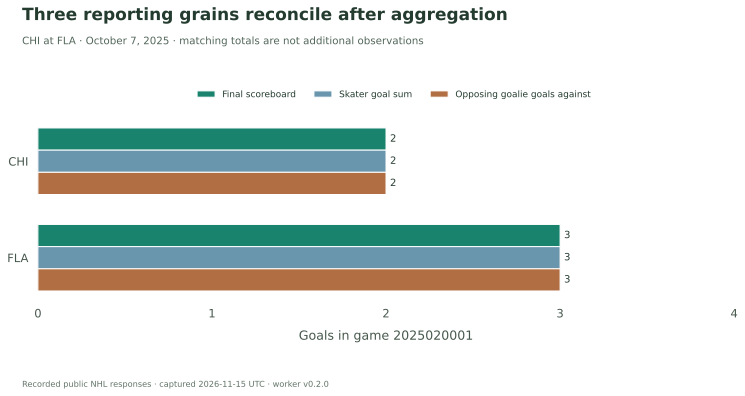

Across the two teams, all three representations agree on **5 goals**. Skater and opposing-goalie shot counts also reconcile to **56 shots on goal**.

In [12]:
display(audit)
fig, ax = plt.subplots(figsize=(11, 5.8))
y = np.arange(len(audit))
width = 0.23
for offset, key, label, color in [
    (-1, "scoreboard_goals", "Final scoreboard", "#19836D"),
    (0, "skater_goals", "Skater goal sum", "#6995AD"),
    (1, "opposing_goalie_goals", "Opposing goalie goals against", "#B16E43"),
]:
    bars = ax.barh(y + offset * width, audit[key], height=width, color=color, label=label)
    ax.bar_label(bars, padding=4, fmt="%g", fontsize=10)
ax.set_yticks(y, audit.team_abbrev)
ax.invert_yaxis()
ax.set_xlim(0, 4)
ax.set_xticks(range(5))
ax.set_xlabel("Goals in game 2025020001")
fig.legend(*ax.get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.54, 0.79), ncol=3, fontsize=9)
finish(
    fig,
    "Three reporting grains reconcile after aggregation",
    "CHI at FLA · October 7, 2025 · matching totals are not additional observations",
    SOURCE,
    name="opener-goals",
)
prose(
    f"Across the two teams, all three representations agree on **{int(audit.scoreboard_goals.sum())} goals**. "
    f"Skater and opposing-goalie shot counts also reconcile to **{int(audit.skater_shots.sum())} shots on goal**."
)

### Preserve a denominator before interpreting a percentage

A backup with zero shots faced has a **NULL** save percentage, not a 0% performance.
The minimum-shots rule selects the comparison population locally. It is not an
NHL qualification rule and does not make one game a reliable measure of ability.
Show saved and conceded shots as counts beside the rate; the threshold changes only
marker fill and eligibility, while the underlying game remains fixed.

In [13]:
%%sql goalie_frame <<
SELECT team_abbrev,player_name,starter,toi_seconds,shots_against,saves,goals_against,save_pct,
 100.0*saves/nullif(shots_against,0) AS calculated_save_pct,
 shots_against>={{MIN_SHOTS}} AS selected FROM goalies ORDER BY team_abbrev,starter DESC,player_id;

,team_abbrev,player_name,starter,toi_seconds,shots_against,saves,goals_against,save_pct,calculated_save_pct,selected
0,CHI,S. Knight,True,3544,37,34,3,0.918919,91.891892,True
1,CHI,A. Soderblom,False,0,0,0,0,NaN,NaN,False
2,FLA,S. Bobrovsky,True,3600,19,17,2,0.894737,89.473684,False
3,FLA,D. Tarasov,False,0,0,0,0,NaN,NaN,False


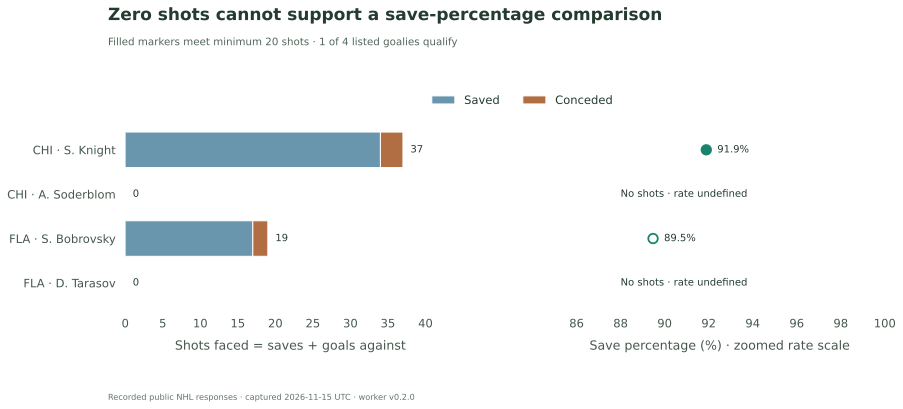

**1 of 4** listed goalies meet the local rule. **2** rows have undefined rates. A higher save percentage here describes this game's observed shots, not a ranking of goalie talent.

In [14]:
display(goalie_frame)
fig, axes = plt.subplots(1, 2, figsize=(12, 6.0), sharey=True)
y = np.arange(len(goalie_frame))
axes[0].barh(y, goalie_frame.saves, color="#6995AD", label="Saved")
axes[0].barh(y, goalie_frame.goals_against, left=goalie_frame.saves, color="#B16E43", label="Conceded")
for i, row in enumerate(goalie_frame.itertuples()):
    axes[0].text(row.shots_against + 1, i, str(row.shots_against), va="center", fontsize=10)
    if row.shots_against:
        axes[1].scatter(
            row.calculated_save_pct,
            i,
            s=90,
            facecolors="#19836D" if row.selected else "white",
            edgecolors="#19836D",
            linewidths=1.8,
        )
        axes[1].text(row.calculated_save_pct + 0.5, i, f"{row.calculated_save_pct:.1f}%", va="center", fontsize=10)
    else:
        axes[1].text(88, i, "No shots · rate undefined", va="center", fontsize=10)
axes[0].set_yticks(y, [f"{r.team_abbrev} · {r.player_name}" for r in goalie_frame.itertuples()])
axes[0].invert_yaxis()
axes[0].set_xlim(0, 44)
axes[0].set_xlabel("Shots faced = saves + goals against")
axes[1].set_xlim(85, 100)
axes[1].set_xlabel("Save percentage (%) · zoomed rate scale")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.55, 0.79), ncol=2)
finish(
    fig,
    "Zero shots cannot support a save-percentage comparison",
    f"Filled markers meet minimum {MIN_SHOTS} shots · {int(goalie_frame.selected.sum())} of {len(goalie_frame)} listed goalies qualify",
    SOURCE,
    name=f"goalie-denominators-{MIN_SHOTS}",
)
prose(
    f"**{int(goalie_frame.selected.sum())} of {len(goalie_frame)}** listed goalies meet the local rule. "
    f"**{int(goalie_frame.save_pct.isna().sum())}** rows have undefined rates. "
    "A higher save percentage here describes this game's observed shots, not a ranking of goalie talent."
)

In [15]:
%%sql checks <<
SELECT 'three source rows for one key' check_name,count(*)=3 AND count(DISTINCT game_id)=1 passed FROM game_versions
UNION ALL SELECT 'same final scores',count(DISTINCT(away_score,home_score))=1 FROM game_versions
UNION ALL SELECT 'same UTC start and season',count(DISTINCT(start_time_utc,season,game_type))=1 FROM game_versions
UNION ALL SELECT 'unique skater keys',count(*)=count(DISTINCT(game_id,player_id)) FROM skaters
UNION ALL SELECT 'unique goalie keys',count(*)=count(DISTINCT(game_id,player_id)) FROM goalies
UNION ALL SELECT 'goals reconcile',bool_and(scoreboard_goals=skater_goals AND skater_goals=opposing_goalie_goals) FROM team_audit
UNION ALL SELECT 'shots reconcile',bool_and(scoreboard_shots=skater_shots AND skater_shots=opposing_goalie_shots) FROM team_audit
UNION ALL SELECT 'goalie shot accounting',bool_and(shots_against=saves+goals_against) FROM goalies
UNION ALL SELECT 'undefined rate exactly without shots',bool_and((save_pct IS NULL)=(shots_against=0)) FROM goalies
UNION ALL SELECT 'returned rate agrees within rounding',bool_and(abs(save_pct-saves::DOUBLE/nullif(shots_against,0))<0.000001) FROM goalies WHERE shots_against>0;

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** " + source.audit())
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-02.json").write_text(
    json.dumps(
        {
            "parameters": {"MIN_SHOTS": MIN_SHOTS, "DATA_MODE": DATA_MODE},
            "scopes": scopes.to_dict("records"),
            "versions": versions.to_dict("records"),
            "audit": audit.to_dict("records"),
            "goalie_frame": goalie_frame.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": source.requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,three source rows for one key,True
1,same final scores,True
2,same UTC start and season,True
3,unique skater keys,True
4,unique goalie keys,True
5,goals reconcile,True
6,shots reconcile,True
7,goalie shot accounting,True
8,undefined rate exactly without shots,True
9,returned rate agrees within rounding,True


**All 10 SQL checks passed.** Exactly 4 recorded HTTP responses requested once each; no unexpected requests.

4668

### Change one thing

Change **MIN_SHOTS 20→1**. Both goalies who faced shots become eligible, while the two backups still have undefined rates. Final scores, all shot counts and the first chart must remain unchanged.

In [17]:
assert not con.execute("SELECT * FROM duckdb_secrets()").fetchall()
session.close()
source.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nhl](https://github.com/Query-farm/vgi-nhl)